# Tutorial: Multilayer Perceptrons in PyTorch

In this tutorial you will build, train and evaluate multilayer perceptrons (MLPs) with **PyTorch** for a classification problem. Along the way you will compare gradient descent with Adam, different learning rates and different network sizes, and choose a final model.

**Contents**

0. Setup: what PyTorch is and how to install it

**Classification**

1. The spiral data
2. Building an MLP in PyTorch
3. Training, validation and test data
4. Training with gradient descent
5. Plotting the training and validation cost
6. Accuracy, precision and recall on the test set
7. Decision boundary
8. Investigation: optimiser, learning rate and network size

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete. Cells marked **Your evaluation** are for you to write your own comments and conclusions.

---
## 0. Setup

### What is PyTorch?

PyTorch is a Python library for building and training neural networks. It gives you:

- **Tensors**: arrays very like NumPy arrays, which can also run on a GPU.
- **Automatic differentiation (autograd)**: PyTorch records the forward pass and works out every gradient $\partial J/\partial w$ for you when you call `.backward()`. This is backpropagation, done automatically.
- **Building blocks** (`torch.nn`): layers such as `nn.Linear`, activations such as `nn.ReLU` and `nn.Sigmoid`, and cost functions such as `nn.BCELoss` and `nn.MSELoss`.
- **Optimisers** (`torch.optim`): gradient descent (`SGD`), Adam and others, which update the weights using those gradients.

So everything you have done by hand (forward pass, backprop, the update $w \leftarrow w - \alpha \, \partial J/\partial w$) is still happening; PyTorch just does the bookkeeping.

### How to install it

- **Google Colab**: PyTorch is already installed.
- **Your own computer**: in a terminal, run `pip install torch` (or `conda install pytorch -c pytorch`). For a GPU version, use the selector at [pytorch.org/get-started](https://pytorch.org/get-started/locally/).
- **From inside this notebook**: uncomment and run the cell below, then restart the kernel.

In [1]:
pip install torch

### Example 0

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


---
# Classification

---
## 1. The spiral data

Two interleaved spirals, one for each class ($y = 0$ and $y = 1$). No straight line (or simple curve) separates them, so a single neuron cannot classify them, but an MLP can.

### Example 1

X shape: (600, 2)   y shape: (600, 1)


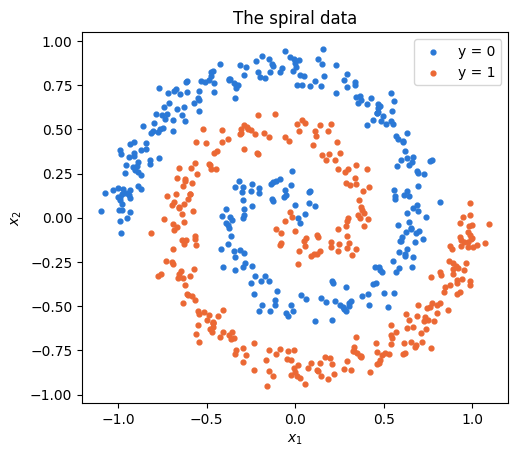

In [3]:
def make_spirals(n=300, noise=0.06, seed=0):
    """Two interleaved spirals with n points each.
    Returns X with shape (2n, 2) and y with shape (2n, 1), both float32 NumPy arrays."""
    rng = np.random.default_rng(seed)
    t = np.sqrt(rng.random(n)) * 3 * np.pi                       # angle along the spiral
    arm = np.c_[t * np.cos(t), t * np.sin(t)] / (3 * np.pi)       # one spiral arm, scaled to radius 1
    arm = arm + noise * rng.normal(size=(n, 2))
    X = np.r_[arm, -arm]                                          # the second arm is the first rotated by 180 degrees
    y = np.r_[np.zeros(n), np.ones(n)].reshape(-1, 1)
    return X.astype(np.float32), y.astype(np.float32)

X, y = make_spirals()
print("X shape:", X.shape, "  y shape:", y.shape)

plt.figure(figsize=(5.5, 5.5))
plt.scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], s=12, c=BLUE, label="y = 0")
plt.scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], s=12, c=ORANGE, label="y = 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.gca().set_aspect("equal")
plt.legend(); plt.title("The spiral data"); plt.show()

---
## 2. Building an MLP in PyTorch

We build the network up in four steps: put the data into a tensor, make one layer, chain layers together, then package it all into a function.

### Example 2a: the data as a tensor

PyTorch works with **tensors** instead of NumPy arrays. A tensor behaves much like an array (it has a shape, you can index and slice it), but PyTorch can also track every calculation done with it, which is what lets it compute gradients automatically.

PyTorch layers expect 32-bit floating-point numbers, so we set `dtype=torch.float32`.

In [4]:
X_t = torch.tensor(X, dtype=torch.float32)

print("shape:", X_t.shape)          # (number of examples n, number of features k), just like X
print("type:", X_t.dtype)
print("first three examples:")
print(X_t[:3])

shape: torch.Size([600, 2])
type: torch.float32
first three examples:
tensor([[ 0.2939,  0.7370],
        [ 0.1126, -0.5864],
        [-0.0169,  0.2632]])


To go back from a tensor to a NumPy array (for example, to plot it), use `.numpy()`.

### Example 2b: one layer with an activation function

`nn.Linear(k, h)` is a layer of $h$ neurons, each with $k$ inputs. It holds the weights and biases of all $h$ neurons and, given $X$ (shape $n \times k$), computes

$$Z = XW + b$$

for all the examples and all the neurons at once. PyTorch stores the weights as `layer.weight` with shape $h \times k$, which is the **transpose** of the $W$ ($k \times h$) we have used in lectures, so in PyTorch's own terms the calculation is `X @ layer.weight.T + layer.bias`.

The activation is a separate object: `nn.ReLU()` applies $\max(0, z)$ to every element, giving $A = \mathrm{ReLU}(Z)$.

Here is a hidden layer of 4 neurons acting on the first 5 examples. The weights start random.

In [5]:
torch.manual_seed(0)
layer1 = nn.Linear(2, 4)            # nn.Linear(in_features, out_features): 4 neurons so 4 output features for next layer, each with 2 inputs (x1, x2)
relu = nn.ReLU()

print("weights, shape", tuple(layer1.weight.shape), "(one row per neuron):")
print(layer1.weight)
print("biases, shape", tuple(layer1.bias.shape), ":")
print(layer1.bias)

Z1 = layer1(X_t[:5])                # pre-activations, shape (5, 4): one row per example, one column per neuron
A1 = relu(Z1)                       # activations: negative values become 0
print("\nZ1 =", Z1)
print("\nA1 =", A1)

# The layer really is computing X W + b (with PyTorch's transposed weights)
print("\nSame as X @ W.T + b?", torch.allclose(Z1, X_t[:5] @ layer1.weight.T + layer1.bias))

weights, shape (4, 2) (one row per neuron):
Parameter containing:
tensor([[-0.0053,  0.3793],
        [-0.5820, -0.5204],
        [-0.2723,  0.1896],
        [-0.0140,  0.5607]], requires_grad=True)
biases, shape (4,) :
Parameter containing:
tensor([-0.0628,  0.1871, -0.2137, -0.1390], requires_grad=True)

Z1 = tensor([[ 0.2153, -0.3675, -0.1540,  0.2701],
        [-0.2858,  0.4268, -0.3555, -0.4693],
        [ 0.0372,  0.0600, -0.1592,  0.0088],
        [-0.0048,  0.0585, -0.2072, -0.0539],
        [ 0.2205,  0.2515,  0.1353,  0.2844]], grad_fn=<AddmmBackward0>)

A1 = tensor([[0.2153, 0.0000, 0.0000, 0.2701],
        [0.0000, 0.4268, 0.0000, 0.0000],
        [0.0372, 0.0600, 0.0000, 0.0088],
        [0.0000, 0.0585, 0.0000, 0.0000],
        [0.2205, 0.2515, 0.1353, 0.2844]], grad_fn=<ReluBackward0>)

Same as X @ W.T + b? True


You will see `grad_fn=...` next to the results. That is PyTorch recording how each number was calculated, so that it can run backprop later.

### Example 2c: chaining layers

The activations of one layer are the inputs of the next. Adding an output layer of 1 neuron with a sigmoid gives a complete (small) MLP: 2 inputs, one hidden layer of 4 ReLU neurons, and one sigmoid output neuron. Its output is $\hat{y}$, the probability that $y = 1$.

In [6]:
layer2 = nn.Linear(4, 1)            # output layer: 1 neuron with 4 inputs (the 4 activations from layer 1)
sigmoid = nn.Sigmoid()

A1 = relu(layer1(X_t[:5]))          # hidden layer on first 5 examples
y_hat = sigmoid(layer2(A1))         # output layer
print("y_hat =", y_hat)             # shape (5, 1): one probability per example (random for now: no training yet)

y_hat = tensor([[0.5249],
        [0.5141],
        [0.5400],
        [0.5445],
        [0.4966]], grad_fn=<SigmoidBackward0>)


`nn.Sequential` does exactly this chaining for us: it passes the input through each item in turn. Here is the same network written as one object, and then a network with **two** hidden layers of 4 neurons. The second hidden layer has 4 neurons each taking 4 inputs, so it is `nn.Linear(4, 4)`.

In [7]:
torch.manual_seed(0)
one_hidden = nn.Sequential(
    nn.Linear(2, 4), nn.ReLU(),     # hidden layer 1
    nn.Linear(4, 1), nn.Sigmoid())  # output layer
print(one_hidden)

two_hidden = nn.Sequential(
    nn.Linear(2, 4), nn.ReLU(),     # hidden layer 1
    nn.Linear(4, 4), nn.ReLU(),     # hidden layer 2
    nn.Linear(4, 1), nn.Sigmoid())  # output layer
print(two_hidden)

y_hat = two_hidden(X_t)             # forward pass on all 600 examples at once
print("output shape:", tuple(y_hat.shape))

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
  (3): Sigmoid()
)
Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=4, bias=True)
  (3): ReLU()
  (4): Linear(in_features=4, out_features=1, bias=True)
  (5): Sigmoid()
)
output shape: (600, 1)


### Exercise 2

Build a network with **three** hidden layers of **8** ReLU neurons each and a sigmoid output, using `nn.Sequential`. Then run it on all of `X_t`.

In [8]:
three_hidden = nn.Sequential(
    nn.Linear(2, 8), nn.ReLU(),     # hidden layer 1
    nn.Linear(8, 8), nn.ReLU(),     # hidden layer 2
    nn.Linear(8, 8), nn.ReLU(),     # hidden layer 3
    nn.Linear(8, 1), nn.Sigmoid())  # output layer
y_hat = three_hidden(X_t)

In [9]:
# Check your answer (should print True)
n_params = sum(p.numel() for p in three_hidden.parameters())
print(n_params == (2 * 8 + 8) + 2 * (8 * 8 + 8) + (8 + 1) and tuple(y_hat.shape) == (600, 1))

True


### Example 2d: the network

For the rest of this notebook we will use one network: **2 hidden layers of 32 ReLU neurons** and a sigmoid output. (You will try other sizes in Section 8.)

We will train this network several times, for example once with gradient descent and once with Adam. For a fair comparison every run should start from **the same initial weights**, so `new_model()` sets the random seed and then builds the `nn.Sequential`. Calling it gives a fresh, untrained copy of the same network.

In [10]:
def new_model():
    """A fresh, untrained copy of our network, always with the same initial weights."""
    torch.manual_seed(0)
    return nn.Sequential(
        nn.Linear(2, 32), nn.ReLU(),       # hidden layer 1: 32 neurons, each with 2 inputs
        nn.Linear(32, 32), nn.ReLU(),      # hidden layer 2: 32 neurons, each with 32 inputs
        nn.Linear(32, 1), nn.Sigmoid())    # output layer: 1 neuron, y_hat = probability that y = 1

def count_parameters(model):
    """Total number of weights and biases in the model."""
    return sum(p.numel() for p in model.parameters())

model = new_model()
print(model)
print("Number of parameters:", count_parameters(model))

Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
  (5): Sigmoid()
)
Number of parameters: 1185


---
## 3. Training, validation and test data

We split the data into three sets:

- **training set** (60%): used to update the weights,
- **validation set** (20%): used to monitor training and to compare models,
- **test set** (20%): used once at the end, to estimate how well the chosen model does on new data.

The examples must be shuffled first: the spiral data are ordered (all of class 0, then all of class 1).

### Exercise 3

In [11]:
def split_data(X, y, frac_train=0.6, frac_val=0.2, seed=0):
    """Shuffle the examples, then split them into training, validation and test sets.
    Returns X_train, y_train, X_val, y_val, X_test, y_test."""
    rng = np.random.default_rng(seed)
    n = len(X)
    idx = rng.permutation(n)
    n_train = int(frac_train * n)
    n_val = int(frac_val * n)
    train_idx = idx[:n_train]
    val_idx = idx[n_train:n_train + n_val]
    test_idx = idx[n_train + n_val:]
    return X[train_idx], y[train_idx], X[val_idx], y[val_idx], X[test_idx], y[test_idx]

In [12]:
X_train, y_train, X_val, y_val, X_test, y_test = split_data(X, y)
print("training:", X_train.shape, " validation:", X_val.shape, " test:", X_test.shape)


# Check your answer (should print True)
rows = {tuple(r) for r in X_train} | {tuple(r) for r in X_val} | {tuple(r) for r in X_test}
print(len(X_train) == 360 and len(X_val) == 120 and len(X_test) == 120 and len(rows) == 600)

training: (360, 2)  validation: (120, 2)  test: (120, 2)
True


As in Example 2a, each part is converted to a 32-bit tensor so that PyTorch can handle the data.

### Example 3

In [13]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

---
## 4. Training with gradient descent

Every PyTorch training loop repeats the same five steps:

| Step | PyTorch | What it does |
|---|---|---|
| 1 | `y_hat = model(X_train_t)` | forward pass: compute $\hat{y}$ for every training example |
| 2 | `J = loss_fn(y_hat, y_train_t)` | cost $J$: the loss $L$ averaged over the examples |
| 3 | `optimiser.zero_grad()` | clear the gradients left over from the last iteration |
| 4 | `J.backward()` | backprop: compute $\partial J / \partial w$ and $\partial J / \partial b$ for every weight and bias |
| 5 | `optimiser.step()` | update every weight, e.g. $w \leftarrow w - \alpha \, \partial J / \partial w$ |

Here every iteration uses all the training examples at once, so this is **batch gradient descent** and one iteration is one epoch.

The validation cost is calculated at the end of each epoch, inside `with torch.no_grad():`, which tells PyTorch not to record anything for backprop, because we are only measuring, not training.

For binary classification the cost function is binary cross-entropy, `nn.BCELoss()`:
$$J = -\frac{1}{n}\sum_{i=1}^{n}\Big[y^{(i)}\log \hat{y}^{(i)} + (1-y^{(i)})\log\big(1-\hat{y}^{(i)}\big)\Big]$$

### Exercise 4 - write the training loop

In [14]:
def train_model(model, optimiser, loss_fn, X_train_t, y_train_t, X_val_t, y_val_t, n_epochs):
    J_train, J_val = [], []
    for epoch in range(n_epochs):
        y_hat = model(X_train_t)             # forward pass
        J = loss_fn(y_hat, y_train_t)        # training cost
        J_train.append(J.item())
        optimiser.zero_grad()                # clear old gradients
        J.backward()                         # backprop
        optimiser.step()                     # update weights and biases

        with torch.no_grad():
            J_v = loss_fn(model(X_val_t), y_val_t)
        J_val.append(J_v.item())
    return J_train, J_val

### Example 4

`torch.optim.SGD` with all the training data in every iteration is plain (batch) gradient descent. The learning rate $\alpha$ is called `lr` in PyTorch.

In [15]:
alpha = 0.1
n_epochs = 2000 # set the number of epochs, or the number of times the model will see the entire training set

model = new_model() # define the model again (a fresh, untrained copy)
optimiser = torch.optim.SGD(model.parameters(), lr=alpha) # choose the optimiser (here gradient descent) and learning rate
loss_fn = nn.BCELoss() # define the loss function (binary cross-entropy for binary classification)

J_train, J_val = train_model(model, optimiser, loss_fn, X_train_t, y_train_t, X_val_t, y_val_t, n_epochs)
print(f"final training cost {J_train[-1]:.3f},  final validation cost {J_val[-1]:.3f}")

final training cost 0.258,  final validation cost 0.290


---
## 5. Plotting the Training and validation cost

### Example 5

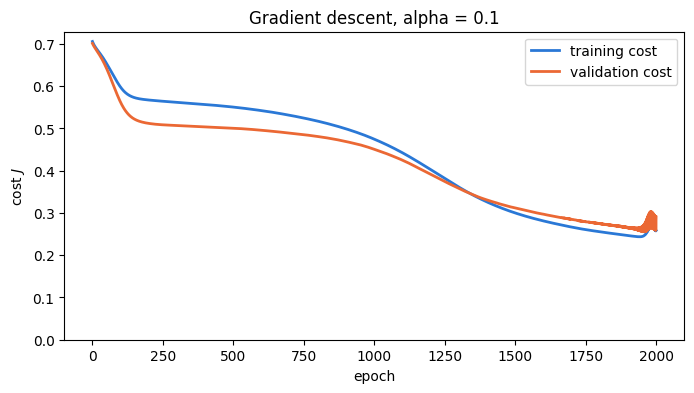

In [16]:
def plot_costs(J_train, J_val, title=""):
    """Training and validation cost against epoch."""
    plt.figure(figsize=(8, 4))
    plt.plot(J_train, color=BLUE, lw=2, label="training cost")
    plt.plot(J_val, color=ORANGE, lw=2, label="validation cost")
    plt.xlabel("epoch"); plt.ylabel("cost $J$"); plt.ylim(bottom=0)
    plt.title(title); plt.legend(); plt.show()

plot_costs(J_train, J_val, f"Gradient descent, alpha = {alpha}")

### Your evaluation 5

*Is the cost still falling at the end? Is there a gap between training and validation cost? Is there any sign of underfitting or overfitting?*

The cost is still falling at epoch 2000 (training 0.258, validation 0.290), so gradient descent with α = 0.1 hasn’t converged. There is a small gap between training and validation cost, but validation isn’t rising, so this isn’t overfitting. The cost is still high, so the model is underfitting because training with plain gradient descent at this learning rate is too slow.

---
## 6. Accuracy, precision and recall on the test set

We turn the network's probabilities into predictions with a threshold of 0.5: predict $1$ if $\hat{y} \geq 0.5$, otherwise $0$. Then, counting over the test examples:

- true positives $TP$: predicted 1 and actually 1,
- false positives $FP$: predicted 1 but actually 0,
- false negatives $FN$: predicted 0 but actually 1,

$$\text{accuracy} = \frac{\text{number correct}}{\text{number of examples}}, \qquad \text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}$$

### Exercise 6

In [17]:
def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    TP = np.sum((y_pred == 1) & (y_true == 1))
    FP = np.sum((y_pred == 1) & (y_true == 0))
    FN = np.sum((y_pred == 0) & (y_true == 1))
    TN = np.sum((y_pred == 0) & (y_true == 0))
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    return accuracy, precision, recall

In [18]:
# Check your answer (should print True)
a, p, r = classification_metrics(np.array([1, 0, 1, 1, 0, 0]), np.array([1, 1, 0, 1, 0, 0]))
print(np.isclose(a, 4 / 6) and np.isclose(p, 2 / 3) and np.isclose(r, 2 / 3))

True


### Example 6

In [19]:
def predict_labels(model, X_t, threshold=0.5):
    """0/1 predictions from a classification model, as a NumPy array."""
    with torch.no_grad():
        y_hat = model(X_t).numpy()
    return (y_hat >= threshold).astype(np.float32)

def report_classification(model):
    """Print accuracy, precision and recall on the test set, and return them."""
    accuracy, precision, recall = classification_metrics(y_test, predict_labels(model, X_test_t))
    print(f"test accuracy {accuracy:.3f},  precision {precision:.3f},  recall {recall:.3f}")
    return accuracy, precision, recall

report_classification(model);

test accuracy 0.850,  precision 0.885,  recall 0.793


### Your evaluation 6

*How good are these numbers? Is precision or recall noticeably lower than the other, and what would that mean here?*

...
Test accuracy is 0.850, precision 0.885 and recall 0.793. These are decent but not great. Recall is noticeably lower than precision, so the model misses about 21% of real class 1 points (false negatives), while when it does predict class 1 it’s usually right. Here that means the boundary is slightly biased towards predicting class 0.

---
## 7. Decision boundary

The decision boundary is where $\hat{y} = 0.5$. We evaluate the network on a fine grid of points and colour each point by its prediction. Training points are shown as dots and test points as stars.

### Example 7

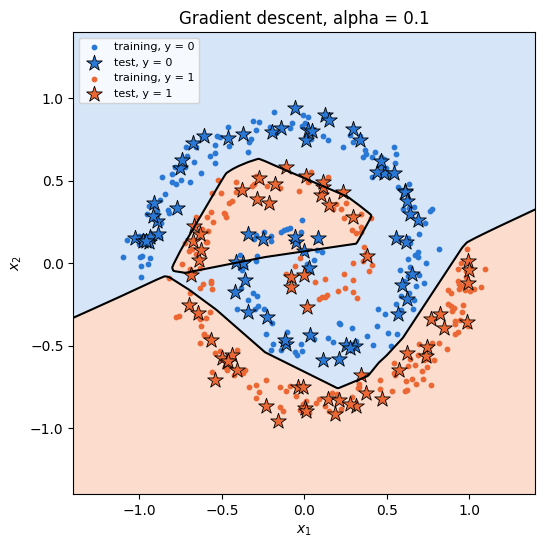

In [20]:
def plot_decision_boundary(model, title=""):
    """Predicted class over the plane, with the training data (dots) and test data (stars)."""
    g = np.linspace(-1.4, 1.4, 300)
    G1, G2 = np.meshgrid(g, g)
    grid_t = torch.tensor(np.c_[G1.ravel(), G2.ravel()], dtype=torch.float32) # unfold the grid into a 2D array of points, shape (300*300, 2)
    with torch.no_grad(): #feed the grid through without computing gradients, since we are not training the model here
        P = model(grid_t).numpy().reshape(G1.shape)
    plt.figure(figsize=(6, 6))
    plt.contourf(G1, G2, P, levels=[0, 0.5, 1], colors=["#d6e6f8", "#fbdccd"])
    plt.contour(G1, G2, P, levels=[0.5], colors="black", linewidths=1.5)
    for cls, c in [(0, BLUE), (1, ORANGE)]:
        tr = y_train[:, 0] == cls
        te = y_test[:, 0] == cls
        plt.scatter(X_train[tr, 0], X_train[tr, 1], s=10, c=c, label=f"training, y = {cls}") # plot the training data
        plt.scatter(X_test[te, 0], X_test[te, 1], s=140, c=c, marker="*", edgecolors="black", linewidths=0.6, label=f"test, y = {cls}") # plot the test data
    plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.gca().set_aspect("equal")
    plt.legend(loc="upper left", fontsize=8); plt.title(title); plt.show()

plot_decision_boundary(model, f"Gradient descent, alpha = {alpha}")

### Your evaluation 7

*Does the boundary follow the spirals? Where are the misclassified test stars?*

...
The boundary only partly follows the spirals: it captures the rough shape but is too smooth and doesn’t wind tightly enough with the arms. The misclassified test stars are mainly near the boundary, where the two arms are close together, which fits the model being underfit after 2000 epochs of gradient descent.

---
## 8. Investigation: optimiser, learning rate and network size

Now you will change one thing at a time and see what happens. To make that quick, first wrap the training and plotting into one function.

**Important:** use the **validation** cost to decide which model is best. The test set is meant to be used only for the final model; we report test metrics for every run here so you can see how they behave, but do not use them to choose.

### Exercise 8a

In [21]:
def train_and_plot(model, optimiser_name, alpha, n_epochs, loss_fn):
    if optimiser_name == "GD":
        optimiser = torch.optim.SGD(model.parameters(), lr=alpha)
    elif optimiser_name == "Adam":
        optimiser = torch.optim.Adam(model.parameters(), lr=alpha)
    else:
        raise ValueError("optimiser_name must be 'GD' or 'Adam'")
    J_train, J_val = train_model(model, optimiser, loss_fn,
                                 X_train_t, y_train_t, X_val_t, y_val_t, n_epochs)
    plot_costs(J_train, J_val, f"{optimiser_name}, alpha = {alpha}, {count_parameters(model)} parameters")
    print(f"final training cost {J_train[-1]:.3f},  final validation cost {J_val[-1]:.3f}")
    return model

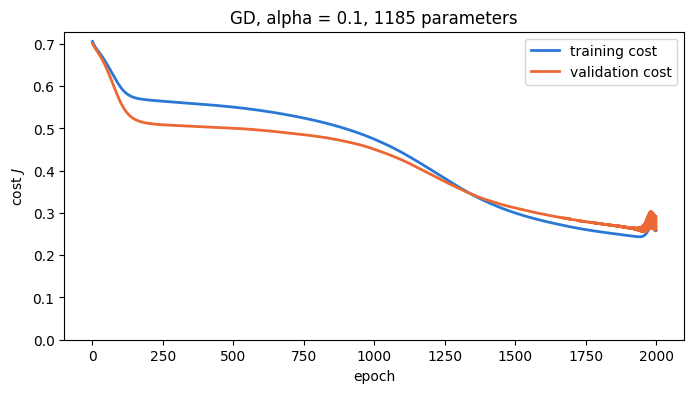

final training cost 0.258,  final validation cost 0.290
test accuracy 0.850,  precision 0.885,  recall 0.793


In [22]:
# Check: this should reproduce your gradient descent run from Section 4 exactly
model = train_and_plot(new_model(), "GD", 0.1, 2000, nn.BCELoss())
report_classification(model);

### Exercise 8b: Adam instead of gradient descent

Train a fresh copy of the same network with Adam. A typical starting learning rate for Adam is $\alpha = 0.01$. Report accuracy, precision and recall, and plot the decision boundary.

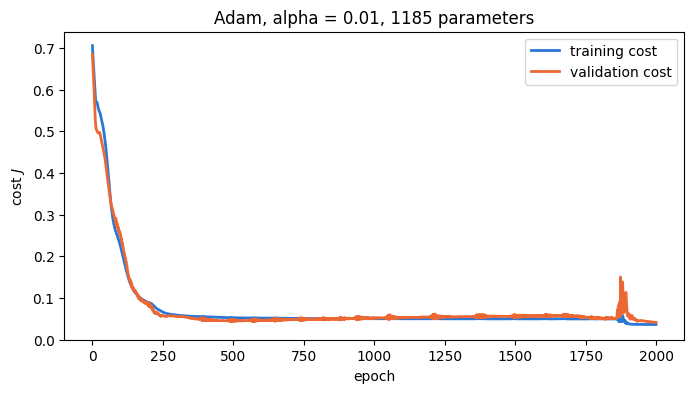

final training cost 0.037,  final validation cost 0.042
test accuracy 0.950,  precision 0.964,  recall 0.931


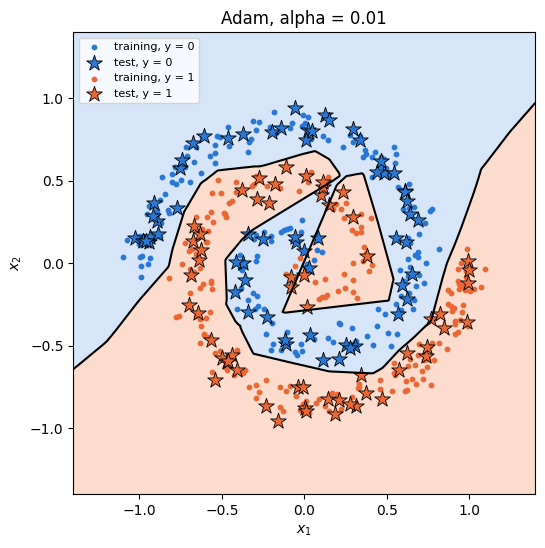

In [23]:
model = train_and_plot(new_model(), "Adam", 0.01, 2000, nn.BCELoss())
report_classification(model)
plot_decision_boundary(model, "Adam, alpha = 0.01")

### Your evaluation 8b

*How do the cost curves compare with gradient descent? Which reaches a low cost faster? Is there any sign of overfitting?*

...
Adam reaches a much lower cost than gradient descent in the same 2000 epochs (training 0.037, validation 0.042 vs 0.258 and 0.290), so it is much faster to converge. Test performance is better too (accuracy 0.950, precision 0.964, recall 0.931). Training and validation cost are very close, so there is no sign of overfitting. The boundary follows the spiral far more closely.

### Exercise 8c: learning rate

Try several learning rates for both optimisers, for example $\alpha$ = 0.001, 0.01, 0.1 and 1 for gradient descent and $\alpha$ = 0.0001, 0.001, 0.01 and 0.1 for Adam. Report the metrics for each.

GD, alpha = 0.001


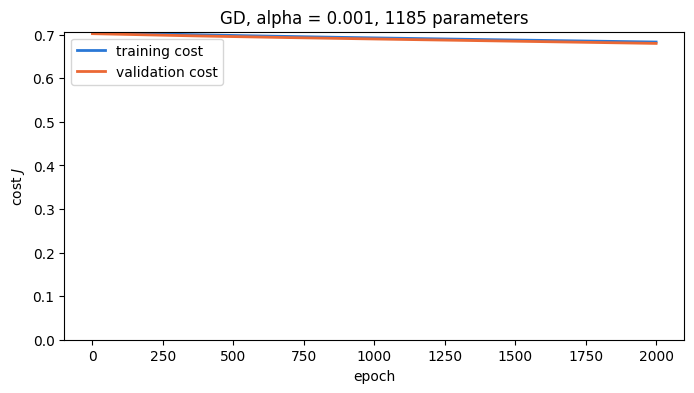

final training cost 0.683,  final validation cost 0.680
test accuracy 0.633,  precision 0.625,  recall 0.603
GD, alpha = 0.01


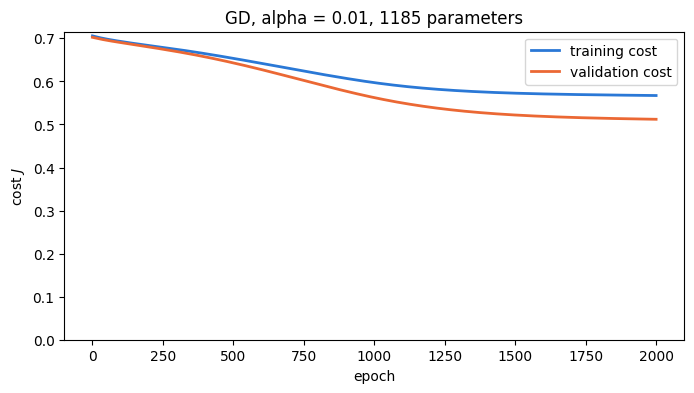

final training cost 0.567,  final validation cost 0.512
test accuracy 0.700,  precision 0.696,  recall 0.672
GD, alpha = 0.1


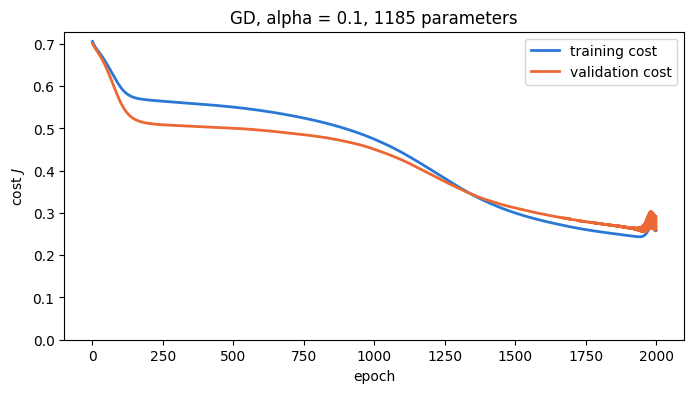

final training cost 0.258,  final validation cost 0.290
test accuracy 0.850,  precision 0.885,  recall 0.793
GD, alpha = 1.0


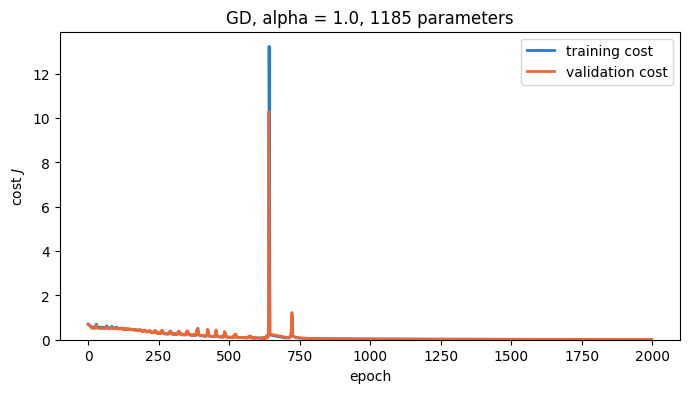

final training cost 0.012,  final validation cost 0.012
test accuracy 0.992,  precision 0.983,  recall 1.000
Adam, alpha = 0.0001


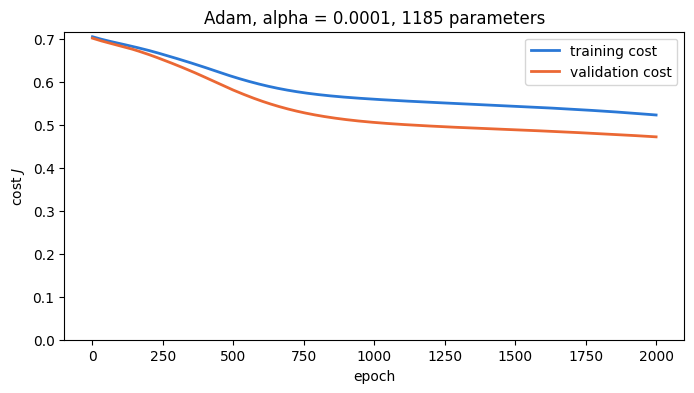

final training cost 0.523,  final validation cost 0.472
test accuracy 0.700,  precision 0.696,  recall 0.672
Adam, alpha = 0.001


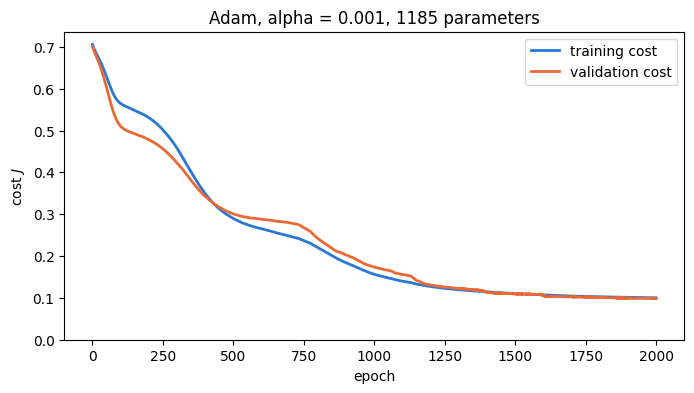

final training cost 0.100,  final validation cost 0.099
test accuracy 0.933,  precision 0.931,  recall 0.931
Adam, alpha = 0.01


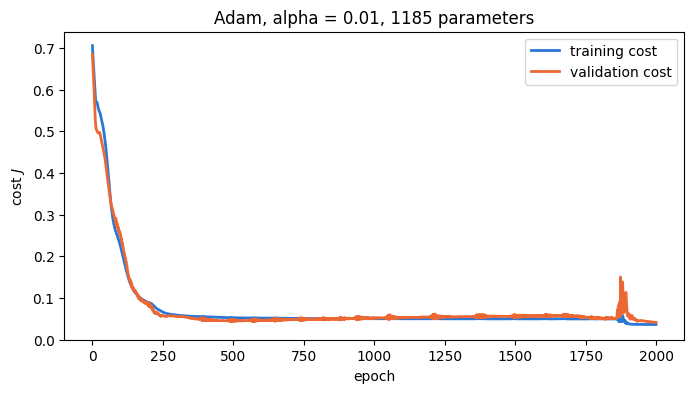

final training cost 0.037,  final validation cost 0.042
test accuracy 0.950,  precision 0.964,  recall 0.931
Adam, alpha = 0.1


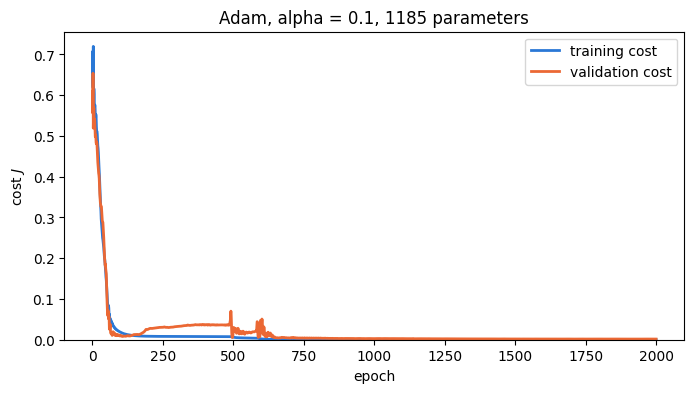

final training cost 0.000,  final validation cost 0.002
test accuracy 1.000,  precision 1.000,  recall 1.000


In [24]:
for alpha in [0.001, 0.01, 0.1, 1.0]:
    print("GD, alpha =", alpha)
    model = train_and_plot(new_model(), "GD", alpha, 2000, nn.BCELoss())
    report_classification(model)

for alpha in [0.0001, 0.001, 0.01, 0.1]:
    print("Adam, alpha =", alpha)
    model = train_and_plot(new_model(), "Adam", alpha, 2000, nn.BCELoss())
    report_classification(model)

### Your evaluation 8c

*What happens when $\alpha$ is too small? Too large? Which learning rate and optimiser would you choose, and why?*

...
When α is too small the cost falls very slowly and the model underfits: GD at α = 0.001 only reaches validation cost 0.680 (accuracy 0.633), and Adam at α = 0.0001 reaches 0.472. For GD, larger was better in this range: α = 1.0 gave the lowest cost (0.012) and 0.992 test accuracy, with no sign of the divergence that a too-large rate would cause. Adam got to a good solution at much smaller rates than GD, and at α = 0.1 it reached validation cost 0.002 and perfect test accuracy.
Adam is the better choice, since it gets good results across a wide range of rates (0.001 to 0.1), while GD only works well at its largest rate. α = 0.1 had the lowest validation cost, but I used α = 0.01 in the rest of the notebook as a safer default, since it is the typical starting rate for Adam and still performed well (validation cost 0.042).

### Exercise 8d: network size

Using your chosen optimiser and learning rate, try networks of different sizes, from small (for example 1 hidden layer of 4 neurons) to large (for example 4 hidden layers of 64 neurons). Write each one as its own `nn.Sequential`, setting the seed first so the results are repeatable. Report the metrics and plot the decision boundary for each.

Network: 1 x 4


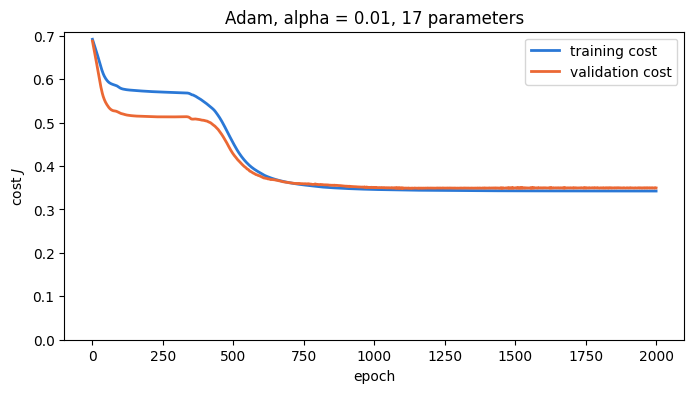

final training cost 0.343,  final validation cost 0.350
test accuracy 0.817,  precision 0.773,  recall 0.879


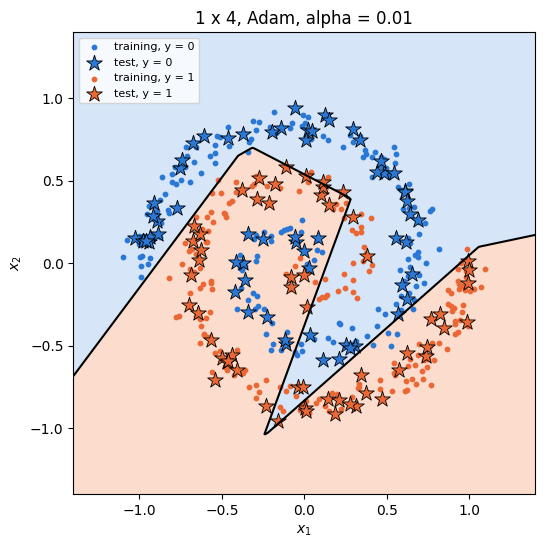

Network: 1 x 16


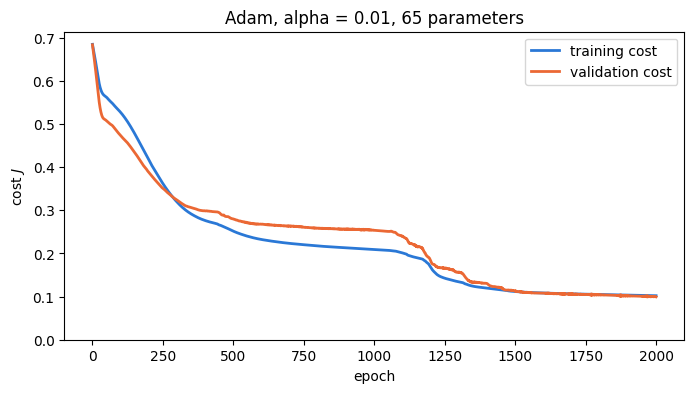

final training cost 0.102,  final validation cost 0.100
test accuracy 0.925,  precision 0.945,  recall 0.897


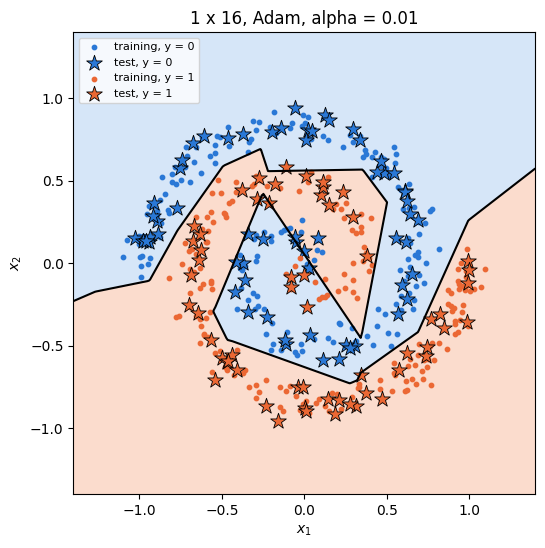

Network: 2 x 64


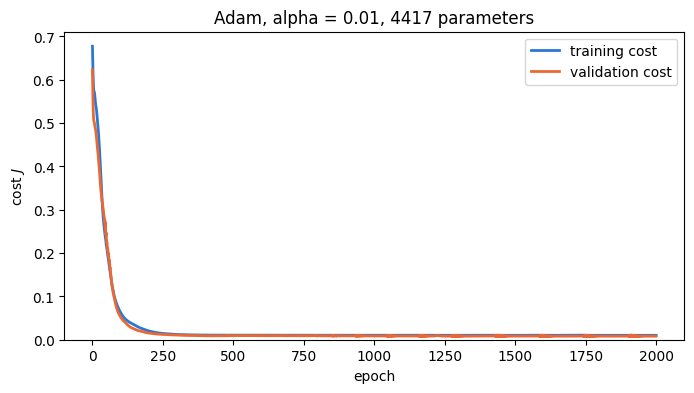

final training cost 0.010,  final validation cost 0.008
test accuracy 0.983,  precision 0.983,  recall 0.983


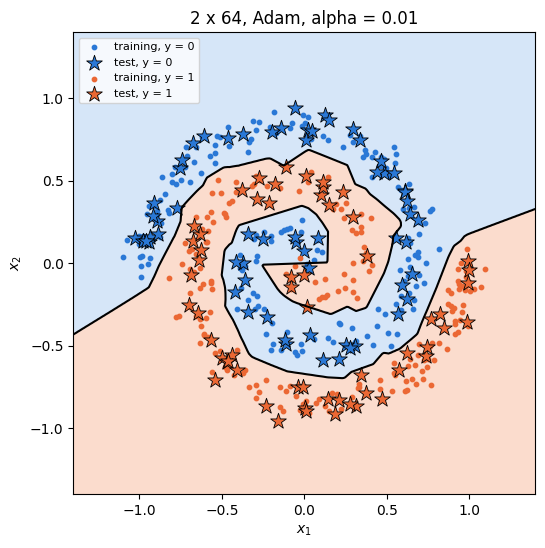

Network: 4 x 64


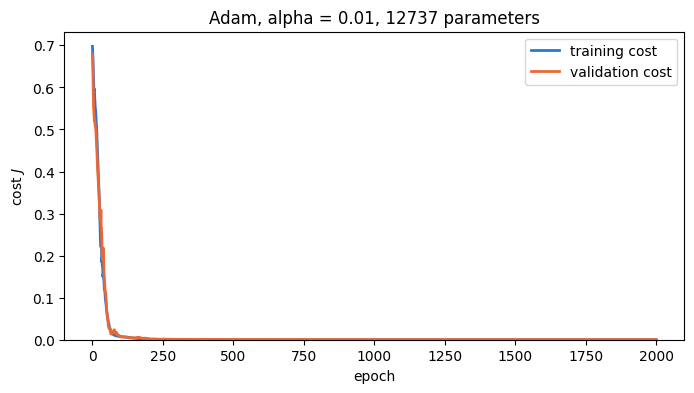

final training cost 0.000,  final validation cost 0.000
test accuracy 0.992,  precision 1.000,  recall 0.983


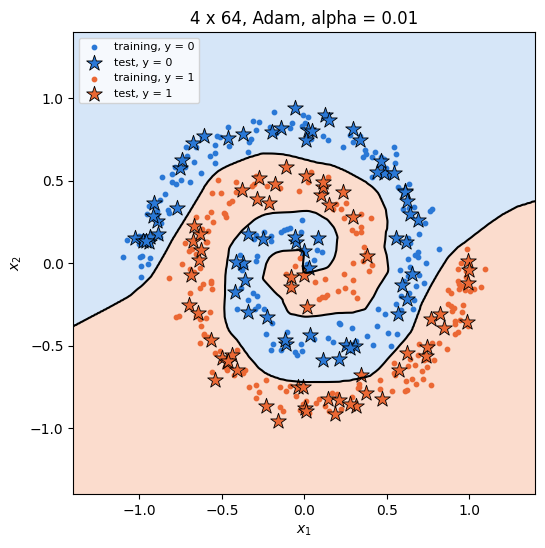

In [25]:
best_optimiser, best_alpha = "Adam", 0.01    # change if your 8c results say otherwise

torch.manual_seed(0)
net_1x4 = nn.Sequential(
    nn.Linear(2, 4), nn.ReLU(),
    nn.Linear(4, 1), nn.Sigmoid())

torch.manual_seed(0)
net_1x16 = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 1), nn.Sigmoid())

torch.manual_seed(0)
net_2x64 = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1), nn.Sigmoid())

torch.manual_seed(0)
net_4x64 = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1), nn.Sigmoid())

networks = {"1 x 4": net_1x4, "1 x 16": net_1x16, "2 x 64": net_2x64, "4 x 64": net_4x64}

for name, net in networks.items():
    print("Network:", name)
    net = train_and_plot(net, best_optimiser, best_alpha, 2000, nn.BCELoss())
    report_classification(net)
    plot_decision_boundary(net, f"{name}, {best_optimiser}, alpha = {best_alpha}")

### Your evaluation 8d

*Which sizes underfit? Do any overfit? How does the number of parameters relate to what you see?*

...
The 1 × 4 network underfits: with only 17 parameters, both its training and validation costs are high (0.343 and 0.350), and its test accuracy is lowest (0.817). 1 × 16 is better (validation cost 0.100) but still limited. 2 × 64 and 4 × 64 fit very well (validation 0.008 and 0.000). None of the networks overfit, since the validation cost is about the same as the training cost in every case. More parameters gave more flexibility and better results, and with 360 low-noise training points even the largest network (4 × 64) didn’t overfit. Beyond 2 × 64, though, the improvement is small.

### Exercise 8e: final model

Choose the best combination of network, optimiser, learning rate and number of epochs, **based on the validation cost**. Train it and present it as your final model: cost curves, test metrics and decision boundary.

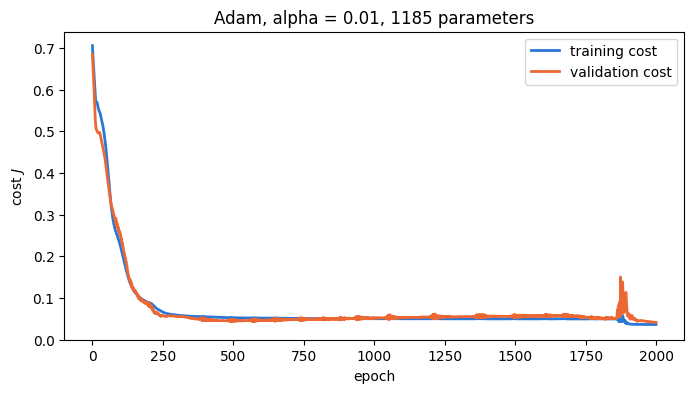

final training cost 0.037,  final validation cost 0.042
test accuracy 0.950,  precision 0.964,  recall 0.931


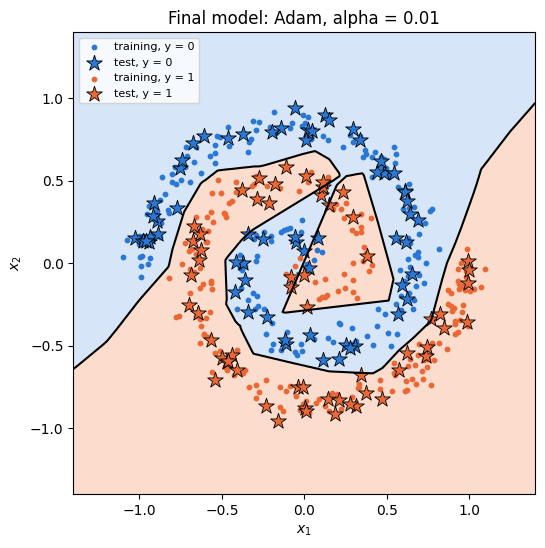

In [26]:
torch.manual_seed(0)
final_model = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1), nn.Sigmoid())
final_optimiser, final_alpha = "Adam", 0.01
final_epochs = 2000

final_model = train_and_plot(final_model, final_optimiser, final_alpha, final_epochs, nn.BCELoss())
report_classification(final_model)
plot_decision_boundary(final_model, f"Final model: {final_optimiser}, alpha = {final_alpha}")

### Your evaluation 8e

*Summarise your final model and justify each choice. How well does it do on the test set?*

...
My final model is a 2 × 32 ReLU network with a sigmoid output, trained with Adam at α = 0.01 for 2000 epochs. I chose Adam because it converged much faster than gradient descent, and α = 0.01 because it’s a stable rate that gave low validation cost (0.042). The 2 × 32 size (1185 parameters) is big enough to fit the spiral, unlike the small networks, without being as large as the 4 × 64 network. On the test set it gets accuracy 0.950, precision 0.964 and recall 0.931. This is close to its validation performance, so the model generalises well, and there is no sign of overfitting. Larger networks or a higher learning rate did a bit better on validation, so the model could be improved further.

### Technical - what needs changing so that you can tackle a regression problem? Re-write the new_model function to do regression and re-train on some synthetic data.

...

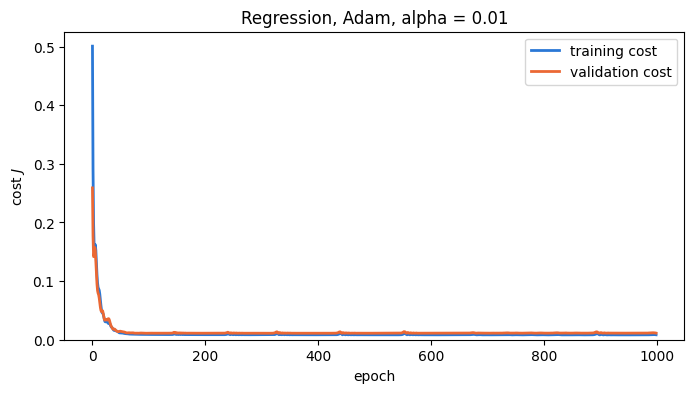

test MSE: 0.009169286116957664


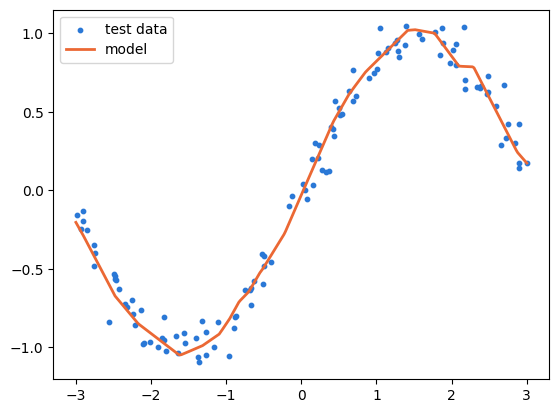

In [27]:
def new_model_regression(n_in=1):
    torch.manual_seed(0)
    return nn.Sequential(
        nn.Linear(n_in, 32), nn.ReLU(),
        nn.Linear(32, 32), nn.ReLU(),
        nn.Linear(32, 1))                # no sigmoid: linear output

# synthetic data: noisy sine wave
rng = np.random.default_rng(0)
Xr = rng.uniform(-3, 3, size=(600, 1)).astype(np.float32)
yr = (np.sin(Xr) + 0.1 * rng.normal(size=Xr.shape)).astype(np.float32)

Xr_tr, yr_tr, Xr_val, yr_val, Xr_te, yr_te = split_data(Xr, yr)
Xr_tr_t, yr_tr_t = torch.tensor(Xr_tr), torch.tensor(yr_tr)
Xr_val_t, yr_val_t = torch.tensor(Xr_val), torch.tensor(yr_val)
Xr_te_t, yr_te_t = torch.tensor(Xr_te), torch.tensor(yr_te)

reg_model = new_model_regression()
opt = torch.optim.Adam(reg_model.parameters(), lr=0.01)
J_train, J_val = train_model(reg_model, opt, nn.MSELoss(),
                             Xr_tr_t, yr_tr_t, Xr_val_t, yr_val_t, 1000)
plot_costs(J_train, J_val, "Regression, Adam, alpha = 0.01")

with torch.no_grad():
    print("test MSE:", nn.MSELoss()(reg_model(Xr_te_t), yr_te_t).item())

# plot the fit
xs = torch.linspace(-3, 3, 300).reshape(-1, 1)
with torch.no_grad():
    plt.scatter(Xr_te, yr_te, s=10, c=BLUE, label="test data")
    plt.plot(xs.numpy(), reg_model(xs).numpy(), c=ORANGE, lw=2, label="model")
plt.legend(); plt.show()